### Dependnecy Setup

In [25]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import pyomo.environ as pyo

### Load Data

In [26]:
# Choose dataset B or C
DATA = "C"

In [27]:
# Generator params and hourly load use semicolon delimiter for both B and C
df_gen_params = pd.read_csv(f'Data/Data{DATA}_generatorparams.csv', sep=';')
df_load = pd.read_csv(f'Data/Data{DATA}_hourlyload.csv', sep=';')

# Non-dispatchable generation uses comma delimiter for C, semicolon for B
nondisp_delimiter = ',' if DATA == "C" else ';'
df_nondisp = pd.read_csv(f'Data/Data{DATA}_nondispgeneration.csv', sep=nondisp_delimiter)

if DATA == "C":
    df_load['load'] = df_load['Total (grid load) [MWh] Calculated resolutions']
    # Set index to 0 to 23 for hours
    df_load.index = np.arange(0, 24)

### Pre-process Non-dispatchable Data (Calculate Expected Values)

To start off, I calculated the expected values for wind and solar using the data from each time window.<br>
This is something that can be changed in the future.

In [28]:
wind_expected = {}
solar_expected = {}

# Helper function to parse ranges like "0-5"
def parse_range(r):
    start, end = map(int, r.split('-'))
    return range(start, end + 1)

# Group by 'hour' column to sum the expected values for that block
grouped = df_nondisp.groupby('hour')

for hour_range_str, group in grouped:
    # Calculate the expected value for this group
    # E = sum(generation * probability)

    # Wind expected value 
    wind_exp = (group['generation wind'] * group['probability wind']).sum()

    # Solar expected value
    solar_exp = (group['generation solar'] * group['probability solar']).sum()

    # Assign this value to every hour in the range
    for hour in parse_range(hour_range_str):
        wind_expected[hour] = wind_exp
        solar_expected[hour] = solar_exp

# Create dataframe for hourly data
hourly_data = pd.DataFrame({
    'load': df_load['load'].astype(float),
    'wind_exp': pd.Series(wind_expected).sort_index(),
    'solar_exp': pd.Series(solar_expected).sort_index()
})

print(hourly_data)

        load  wind_exp  solar_exp
0   50219.75   22200.0        0.0
1   48657.00   22200.0        0.0
2   48689.00   22200.0        0.0
3   49895.50   22200.0        0.0
4   51134.75   22200.0        0.0
5   54662.25   22200.0        0.0
6   61562.75   22200.0     5500.0
7   66396.00   22200.0     5500.0
8   68569.50   22200.0     5500.0
9   70653.25   22200.0     5500.0
10  72214.50   22200.0     5500.0
11  72710.50   22200.0    10400.0
12  71735.50   22200.0    10400.0
13  70005.50   22200.0    10400.0
14  68428.00   22200.0    10400.0
15  66736.25   22200.0     5500.0
16  65774.25   22200.0     5500.0
17  65269.50   22200.0     5500.0
18  66352.75   22200.0     5500.0
19  66179.75   22200.0     5500.0
20  62462.25   24700.0        0.0
21  59083.00   24700.0        0.0
22  56607.00   24700.0        0.0
23  53307.25   24700.0        0.0


### Model Initialization

In [29]:
model = pyo.ConcreteModel(name="Unit Commitment Stage 1")

# Sets 
# Generators [1, 2, 3]
model.G = pyo.Set(initialize=df_gen_params['generator'].tolist())

# Time steps [0, 1, ..., 23]
model.T = pyo.Set(initialize=hourly_data.index.tolist())

### Parameters

In [30]:
# Parameters for Generators 
model.a1 = pyo.Param(model.G, initialize=df_gen_params.set_index('generator')['a1'].to_dict())
model.a2 = pyo.Param(model.G, initialize=df_gen_params.set_index('generator')['a2'].to_dict())
model.p_min = pyo.Param(model.G, initialize=df_gen_params.set_index('generator')['pmin'].to_dict())
model.p_max = pyo.Param(model.G, initialize=df_gen_params.set_index('generator')['pmax'].to_dict())

# Parameters for Hourly Data 
model.hourly_load = pyo.Param(model.T, initialize=hourly_data['load'].to_dict())
model.wind_exp = pyo.Param(model.T, initialize=hourly_data['wind_exp'].to_dict())
model.solar_exp = pyo.Param(model.T, initialize=hourly_data['solar_exp'].to_dict())

### Decision Variables

In [31]:
# u[g, t]: Binary status of dispatchable gneerator g at time t (1 if on, 0 if off)
model.u = pyo.Var(model.G, model.T, domain=pyo.Binary)

# p[g, t]: Power output of dispatchable generator g at time t (non-negative)
model.p = pyo.Var(model.G, model.T, domain=pyo.NonNegativeReals)

# u_wind[t], u_solar[t]: Binary status of non-dispatchable generators at time t
model.u_wind = pyo.Var(model.T, domain=pyo.Binary)
model.u_solar = pyo.Var(model.T, domain=pyo.Binary)

### Objective Function

In [32]:
def objective_rule(m):
    # Sum over all generators (g) and all hours (t)
    return sum(m.a2[g] * m.p[g, t]**2 + m.a1[g] * m.p[g, t] for g in m.G for t in m.T)

model.obj = pyo.Objective(rule=objective_rule, sense=pyo.minimize)

### Constraints

In [33]:
# Minimum Generation
def p_min_rule(m, g, t):
    return m.p[g, t] >= m.u[g, t] * m.p_min[g]
model.C_p_min = pyo.Constraint(model.G, model.T, rule=p_min_rule)

# Maximum Generation
def p_max_rule(m, g, t):
    return m.p[g, t] <= m.u[g, t] * m.p_max[g]
model.C_p_max = pyo.Constraint(model.G, model.T, rule=p_max_rule)

# Power Balance
def p_balance_rule(m, t):
    dispatchable_gen = sum(m.p[g, t] for g in m.G)
    nondispatchable_gen = (m.u_wind[t] * m.wind_exp[t]) + (m.u_solar[t] * m.solar_exp[t])
    return dispatchable_gen + nondispatchable_gen == m.hourly_load[t]
model.C_p_balance = pyo.Constraint(model.T, rule=p_balance_rule)

### Solving with NEOS

In [34]:
# Setup Solver Manager
solver_manager = pyo.SolverManagerFactory('neos')

# Select Solver
solver_name = 'cplex' 

# Your email address (required for NEOS)
os.environ['NEOS_EMAIL'] = 'jonas.streuff@tum.de'

print(f"Sending model to NEOS using {solver_name}...")

# Send to NEOS
results = solver_manager.solve(model, opt=solver_name)
print(f"Solver Status: {results.solver.status}")
print(f"Termination Condition: {results.solver.termination_condition}")

# If successful, we extract the results
if results.solver.termination_condition == pyo.TerminationCondition.optimal:
    print("Optimal solution found.")
else:
    print("Warning: Optimal solution not found.")


Sending model to NEOS using cplex...
Solver Status: ok
Termination Condition: optimal
Optimal solution found.


### Print Results

In [35]:
def get_timeseries(variable, generator_idx=None, is_binary=False):
    data = []
    for t in sorted(model.T):
        if generator_idx is not None:
            val = variable[generator_idx, t].value
        else:
            val = variable[t].value
        if val is None:
            val = 0.0
        if is_binary:
            val = round(val)
        data.append(val)
    return data

load_data = [model.hourly_load[t] for t in sorted(model.T)]
wind_exp = [model.wind_exp[t] for t in sorted(model.T)]
solar_exp = [model.solar_exp[t] for t in sorted(model.T)]

u_wind = get_timeseries(model.u_wind, is_binary=True)
u_solar = get_timeseries(model.u_solar, is_binary=True)

gen_ids = sorted(model.G)
p_gen_data = {}
u_gen_data = {}

for g in gen_ids:
    p_gen_data[g] = get_timeseries(model.p, generator_idx=g)
    u_gen_data[g] = get_timeseries(model.u, generator_idx=g, is_binary=True)

# 3. Print the Formatted Table
print("\n" + "="*90)
print(f"OPTIMIZATION RESULTS - Total Cost: {pyo.value(model.obj):,.2f} €")
print("="*90)

# Build Header
# Fixed Columns
header = f"{'Hr':<3} | {'Load':<6} | {'Wind':<5} {'U':<2} | {'Solar':<5} {'U':<2} | "
# Dynamic Columns (one pair per generator)
for g in gen_ids:
    header += f"G{g} (P)   G{g}(U) | "
print(header)
print("-" * len(header))

# Print Rows
for t in range(24):
    # Base Data (Load + Renewables)
    # We cast to int/float for clean formatting
    row = (f"{t:<3} | {load_data[t]:<6.0f} | "
           f"{wind_exp[t]:<5.0f} {int(u_wind[t]):<2} | "
           f"{solar_exp[t]:<5.0f} {int(u_solar[t]):<2} | ")
    
    # Generator Data
    for g in gen_ids:
        p_val = p_gen_data[g][t]
        u_val = int(u_gen_data[g][t])
        
        # Visual cleanup: if generator is OFF, show Power as 0.0
        if u_val == 0:
            p_val = 0.0
            
        row += f"{p_val:<8.1f} {u_val:<5} | "
    
    print(row)

print("-" * len(header))


OPTIMIZATION RESULTS - Total Cost: 305,218,611.78 €
Hr  | Load   | Wind  U  | Solar U  | G1 (P)   G1(U) | G2 (P)   G2(U) | G3 (P)   G3(U) | G4 (P)   G4(U) | 
---------------------------------------------------------------------------------------------------------
0   | 50220  | 22200 1  | 0     0  | 2164.9   1     | 1800.0   1     | 12000.0  1     | 12054.9  1     | 
1   | 48657  | 22200 1  | 0     0  | 2000.0   1     | 1800.0   1     | 12000.0  1     | 10657.0  1     | 
2   | 48689  | 22200 1  | 0     0  | 2000.0   1     | 1800.0   1     | 12000.0  1     | 10689.0  1     | 
3   | 49896  | 22200 1  | 0     0  | 2115.4   1     | 1800.0   1     | 12000.0  1     | 11780.1  1     | 
4   | 51135  | 22200 1  | 0     0  | 2304.5   1     | 1800.0   1     | 12000.0  1     | 12830.3  1     | 
5   | 54662  | 22200 1  | 0     0  | 3643.2   1     | 1819.1   1     | 12000.0  1     | 15000.0  1     | 
6   | 61563  | 22200 1  | 5500  1  | 4576.8   1     | 2285.9   1     | 12000.0  1     | 15000.0  1 

### Plot Results

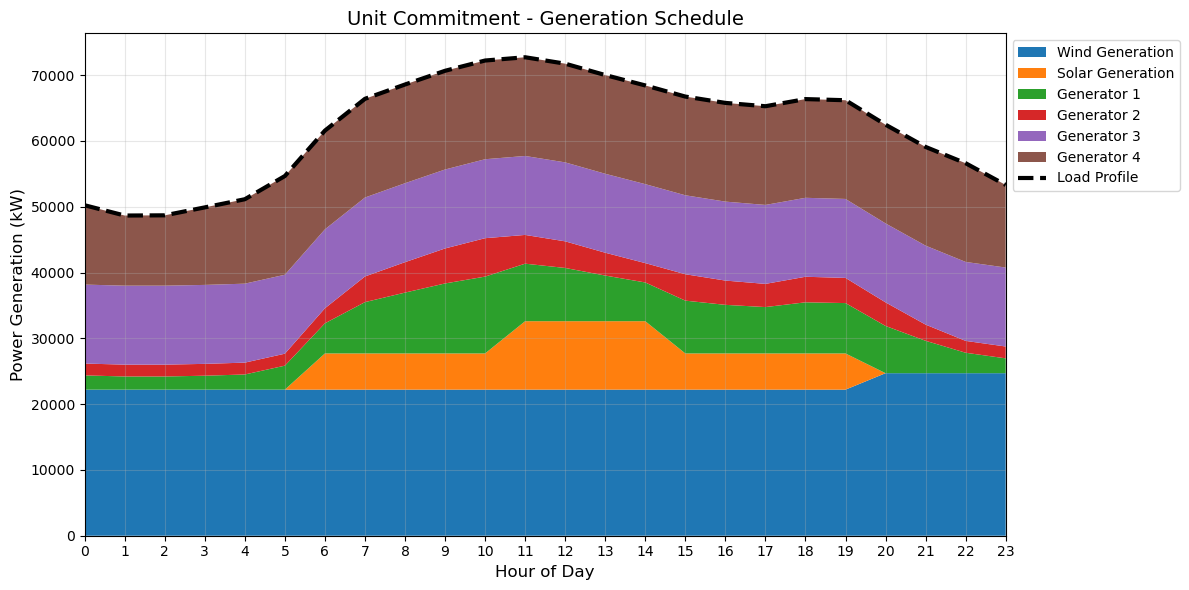

In [36]:
hours = sorted(model.T)

# Dispatchable Generation
wind_gen = []
solar_gen = []
dispatchable_gen = {g: [] for g in gen_ids}

for t in hours:
    wind_gen.append(u_wind[t] * wind_exp[t])
    solar_gen.append(u_solar[t] * solar_exp[t])

    for g in gen_ids:
        dispatchable_gen[g].append(p_gen_data[g][t])


plt.figure(figsize=(12,6))

if DATA == "B":
    plt.stackplot(hours, wind_gen, solar_gen, dispatchable_gen[1], dispatchable_gen[2], dispatchable_gen[3],
              labels=['Wind Generation', 'Solar Generation', 'Generator 1', 'Generator 2', 'Generator 3'],
              colors=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'])
elif DATA == "C":
    plt.stackplot(hours, wind_gen, solar_gen, dispatchable_gen[1], dispatchable_gen[2], dispatchable_gen[3], dispatchable_gen[4],
              labels=['Wind Generation', 'Solar Generation', 'Generator 1', 'Generator 2', 'Generator 3', 'Generator 4'],
              colors=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b'])


plt.plot(hours, load_data, color='black', linewidth=3, label='Load Profile', linestyle='--')

plt.title("Unit Commitment - Generation Schedule", fontsize=14)
plt.xlabel("Hour of Day", fontsize=12)
plt.ylabel("Power Generation (kW)", fontsize=12)
plt.xlim(0, 23)
plt.xticks(hours)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.tight_layout()
plt.savefig(f"Data/Figures/Generation_Schedule_Data{DATA}.png")
plt.show()